# 图 7-5　出生—死亡网络的四项宏观规律

对应书稿第七章图 7-5（依 Schich et al. (2014) *Science* 345:558–562 **图 2** 重绘，
仅 Freebase 库 120,211 人）。

| 面板 | 内容 | 口径要点 |
|---|---|---|
| A | Heaps 律：个体数 N 与地点数 S 的次线性增长 | 参数曲线 (N(t), S(t))：N=按年累计个体数，S=累计**不同**地点数（expanding 去重，不可对各年 nunique 再求和）；参考线 = S∝N⁰·⁹ |
| B | 出生地/死亡地频次的幂律指数随世纪演变 | **ante 累计箱**（bin c = 事件年 ≤ c 世纪末全部记录）+ Clauset et al. (2009) 离散幂律 MLE，xmin 由 KS 最小化自动选择（powerlaw 包）；y = pdf 指数 γ。注：powerlaw 库版本会影响 KS 自动搜索在平局处的选择，故同时输出固定 SM 标注 xmin 的对照 γ（`gamma_*_fixed` 列） |
| C | 出生—死亡距离 Δr 的胖尾分布按出生世纪叠加 | 含同城对（x=1 处尖峰 = 同城比例）；对数 20 箱（1→2×10⁴ km）由原图像元反推；竖线 = 各世纪中位距离（U 形） |
| D | 12 座主要城市死亡份额随世纪涨落 | 份额为 0 的（城市，世纪）断线不画；颜色取自原图图例像元采样，另配独立标记形状 |

**世纪口径**：按死亡年划分，"0–13" = 1300 年前，14–21 = 各世纪（1300–1399 为 14 世纪）。

**数据**：`records_fixed.pkl`（论文随文补充材料 S1 的 Freebase 子集，
由 `records.pkl` 转换而来；records.pkl 由旧版 pandas 序列化，当前环境无法直接反序列化）。

**输出**：`figures/fig2_four_panels_notebook.png` + `results_fig2_notebook.json`。

In [1]:
import contextlib, io, json, os, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import powerlaw
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
print("powerlaw", powerlaw.__version__, "|", powerlaw.__file__)

HERE = Path.cwd()
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "Songti SC", "PingFang SC"],
    "font.family": "sans-serif",
    "axes.unicode_minus": False,
    "font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.7, "figure.dpi": 110, "savefig.dpi": 300,
    "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.5,
})
C_BLUE, C_RED = "#1F6FB4", "#A32626"
EARTH_R = 6371.0088
print("powerlaw", powerlaw.__version__, "| matplotlib", matplotlib.__version__)

powerlaw 1.5 | C:\ProgramData\Anaconda3\Lib\site-packages\powerlaw.py
powerlaw 1.5 | matplotlib 3.11.0


In [2]:
# ---------- 1. 数据：FB 库个体记录、世纪分箱、大圆距离 ----------

rec = pd.read_pickle(HERE / "records_fixed.pkl")
fb = rec[rec.Source == "FB"].copy()
print(f"FB 库 {len(fb)} 人")

BIN_OF = lambda y: np.where(np.asarray(y) < 1300, 0, np.asarray(y) // 100 + 1)
BIN_LABELS = ["0-13", "14", "15", "16", "17", "18", "19", "20", "21"]
CENT = BIN_LABELS  # x 轴刻度

fb["bcent"] = BIN_OF(fb.BYear.values)
fb["dcent"] = BIN_OF(fb.DYear.values)


def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * EARTH_R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

FB 库 120211 人


In [3]:
# ---------- 2. 面板 A：Heaps 律（参数曲线 + 累计去重） ----------

def cum_curve(year, key):
    """按年聚合的参数曲线 (N(t), S(t))：N = 累计个体数（阶梯），
    S = 累计不同地点数 —— 逐年扩张去重，等价于统计「首次出现年份 ≤ t」
    的地点数。【易错】对各年 nunique 结果再做 cumsum 会把跨年重复地点
    重复累计（S 从 24,581 虚增到 92,034，曲线几乎贴住斜率 1）。"""
    d = fb.sort_values(year)
    gy = d.groupby(year, sort=True)
    n = gy.size().cumsum().values
    first_year = d.groupby(key)[year].min().values   # 每个地点首次出现年
    s = np.array([(first_year <= t).sum() for t in gy.size().index], float)
    return n, s


nb_, sb = cum_curve("BYear", "bkey")
nd, sd = cum_curve("DYear", "dkey")
print(f"Heaps 曲线终点：birth N={nb_[-1]} S={sb[-1]}；death N={nd[-1]} S={sd[-1]}"
      f"（全库去重 bkey={fb.bkey.nunique()}，dkey={fb.dkey.nunique()}）")


def loglog_slope(x, y, xmin=10):
    m = (x >= xmin) & (y > 0)
    return np.polyfit(np.log10(x[m]), np.log10(y[m]), 1)[0]


a_birth, a_death = loglog_slope(nb_, sb), loglog_slope(nd, sd)
print(f"Heaps 指数（累计去重曲线，N≥10 拟合）：birth a={a_birth:.3f}，"
      f"death a={a_death:.3f}（论文按增长率比 a=s/r≈0.9）")

Heaps 曲线终点：birth N=120211 S=24581.0；death N=120211 S=17057.0（全库去重 bkey=24581，dkey=17057）
Heaps 指数（累计去重曲线，N≥10 拟合）：birth a=0.858，death a=0.829（论文按增长率比 a=s/r≈0.9）


In [4]:
# ---------- 3. 面板 B：幂律指数随世纪（ante 累计箱 + KS 自动 xmin） ----------

BINS = [0] + list(range(14, 22))


def ante_freqs(col, cent, c):
    """ante 累计箱的地点频次数组：事件年 ≤ c 世纪末（c=0 即 1300 年前）。
    未知地点不计入频次分布：原 records.pkl 用字符串 'nan'，抢救后的
    records_fixed.pkl 中缺失为浮点 NaN，两者都要过滤。"""
    sel = fb[fb[cent] <= c] if c > 0 else fb[fb[cent] == 0]
    keys = sel[col].values
    keys = keys[(keys != "nan") & ~pd.isna(keys)]
    return np.array(list(Counter(keys).values()), float)


def boot_sigma(freqs, xmin, B=100, seed=0):
    """固定 xmin 的 bootstrap ±1σ（对地点频次自助重抽样后重拟合）"""
    v = np.asarray(freqs, float)
    v = v[v >= xmin]
    if v.size < 10:
        return np.nan
    rng = np.random.default_rng(seed)
    gs = [_disc_gamma_at(rng.choice(v, v.size, replace=True), xmin) for _ in range(B)]
    return float(np.nanstd(gs))


def _disc_gamma_at(freqs, xmin):
    """精确离散幂律 MLE（zeta 归一化，截断至样本最大值），返回 pdf 指数 γ"""
    v = np.asarray(freqs, float)
    v = v[v >= xmin]
    if v.size < 5:
        return np.nan
    m = np.log(v).mean()
    xs = np.arange(xmin, v.max() + 1, dtype=float)
    lg = np.log(xs)

    def ratio(g):
        w = xs ** (-g)
        return (lg * w).sum() / w.sum()

    lo, hi = 1.01, 12.0
    for _ in range(50):                 # ratio 单调递减于 γ
        mid = (lo + hi) / 2
        if ratio(mid) > m:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


rows = []
SM_XMIN_B = [1, 1, 1, 1, 1, 2, 3, 7, 7]   # SM fig. S10G 标注（births）
SM_XMIN_D = [1, 1, 1, 1, 1, 1, 2, 1, 1]   # SM fig. S10G 标注（deaths）
for i, c in enumerate(BINS):
    fr_b = ante_freqs("bkey", "bcent", c)     # births 按出生世纪累计
    fr_d = ante_freqs("dkey", "dcent", c)     # deaths 按死亡世纪累计
    with contextlib.redirect_stdout(io.StringIO()):   # 静音 powerlaw 的 xmin progress
        fitb = powerlaw.Fit(fr_b, discrete=True, verbose=False)   # KS 自动选 xmin
        fitd = powerlaw.Fit(fr_d, discrete=True, verbose=False)
    # 对照口径：固定 SM fig. S10G 标注的 xmin（论文自己标注的拟合窗口），
    # 用离散幂律 zeta MLE 重估 γ。powerlaw 各版本（1.3.4–1.5）的 KS 自动
    # 搜索在该数据上一致，但与另一环境的复现相比，KS 相近处会出现平局
    # 翻转，γ 随 xmin 选择系统性移动约 0.1；固定 xmin 可把库版本差异隔离。
    gb = _disc_gamma_at(fr_b, SM_XMIN_B[i])
    gd = _disc_gamma_at(fr_d, SM_XMIN_D[i])
    rows.append(dict(bin=BIN_LABELS[i],
                     n_birth=int(fr_b.sum()), n_death=int(fr_d.sum()),
                     slope_birth=fitb.power_law.alpha, xmin_birth=int(fitb.xmin),
                     se_birth=boot_sigma(fr_b, int(fitb.xmin)),
                     slope_death=fitd.power_law.alpha, xmin_death=int(fitd.xmin),
                     se_death=boot_sigma(fr_d, int(fitd.xmin)),
                     gamma_birth_fixed=round(gb, 3), gamma_death_fixed=round(gd, 3)))
slope_df = pd.DataFrame(rows)
print(slope_df.to_string(index=False))
print("SM fig. S10G 标注 xmin → births: [1,1,1,1,1,2,3,7,7]；deaths: [1,1,1,1,1,1,2,1,1]")

 bin  n_birth  n_death  slope_birth  xmin_birth  se_birth  slope_death  xmin_death  se_death  gamma_birth_fixed  gamma_death_fixed
0-13     1181     1011     2.401625           2  0.115743     2.461889           2  0.172722              2.506              2.621
  14     1591     1329     2.291261           2  0.097324     2.498334           4  0.201246              2.435              2.502
  15     2665     1891     2.340151           3  0.105645     2.266859           3  0.109813              2.389              2.391
  16     4802     3433     2.259261           3  0.067993     2.121861           2  0.067552              2.264              2.253
  17     7668     5932     2.133190           3  0.049678     2.015726           2  0.045065              2.232              2.166
  18    16263     9251     2.131561           3  0.036578     1.973674           3  0.047175              2.121              2.141
  19    68822    25461     2.057019           3  0.016552     1.990161           3 

In [5]:
# ---------- 4. 面板 C：距离分布（含同城）与各世纪中位距离 ----------

sub = fb.dropna(subset=["BLat", "DLat"]).copy()
sub["dr"] = haversine(sub.BLat.values, sub.BLon.values,
                      sub.DLat.values, sub.DLon.values)
print(f"距离样本（含同城）{len(sub)} 条；同城占 {(sub.bkey == sub.dkey).mean():.1%}")

med_by_bin = sub.groupby("dcent").dr.median()      # 含同城，U 形
print("各世纪中位距离（km）：")
print(med_by_bin.round(1).to_string())

# 对数分箱 20 箱（1→2×10⁴ km，相邻间距 0.215 decade，由原图 marker 列像元反推）；
# 第一个点（Δr<1km，基本=同城对）单独计算，画在 x=1
EDGES = np.logspace(0, np.log10(2.0e4), 21)
centers = np.sqrt(EDGES[:-1] * EDGES[1:])
widths = np.diff(EDGES)

距离样本（含同城）120211 条；同城占 14.5%
各世纪中位距离（km）：
dcent
0     214.3
14    165.4
15    152.1
16    165.5
17    135.2
18    174.0
19    261.9
20    381.9
21    364.4


In [6]:
# ---------- 5. 面板 D：12 城死亡份额（按世纪） ----------

# 城市与颜色均取自原图图例像元采样；份额为 0 的（城市, 世纪）断线不画
CITY_KEY = {  # dkey: (论文图例名, 颜色, 是否淡色, 标记形状, 线型)
    "florence":      ("Florence", "#FDED8F", False, "o", "-"),
    "rome":          ("Rome", "#BC0F08", False, "s", "-"),
    "paris":         ("Paris", "#F52423", False, "^", "-"),
    "los angeles":   ("Los Angeles", "#3280F6", False, "v", "-"),
    "new york city": ("New York City", "#56DCF9", False, "D", "-"),
    "london":        ("London", "#F96BA6", False, "<", "-"),
    "moscow":        ("Moscow", "#2F351C", False, ">", "-"),
    "berlin":        ("Berlin", "#ED6126", False, "p", "-"),
    "munich":        ("Munich", "#FBC526", False, "*", "-"),
    "vienna":        ("Vienna", "#AD4B24", False, "X", "-"),
    "amsterdam":     ("Amsterdam", "#FBA162", False, "h", "-"),
    "nuremberg":     ("Nuremberg", "#F5CDBB", True, "d", "-"),
}
missing = [k for k in CITY_KEY if k not in set(fb.dkey)]
if missing:
    print("未匹配到的城市标签:", missing)

share = (fb.groupby(["dcent", "dkey"]).size().unstack(fill_value=0))
share = share.reindex(BINS, fill_value=0)
share = share.div(share.sum(axis=1), axis=0)          # 每世纪死亡份额
print("巴黎各世纪死亡份额：")
print(share["paris"].round(4).to_string())

巴黎各世纪死亡份额：
dcent
0     0.0069
14    0.0252
15    0.0107
16    0.0279
17    0.0668
18    0.1124
19    0.0613
20    0.0219
21    0.0154


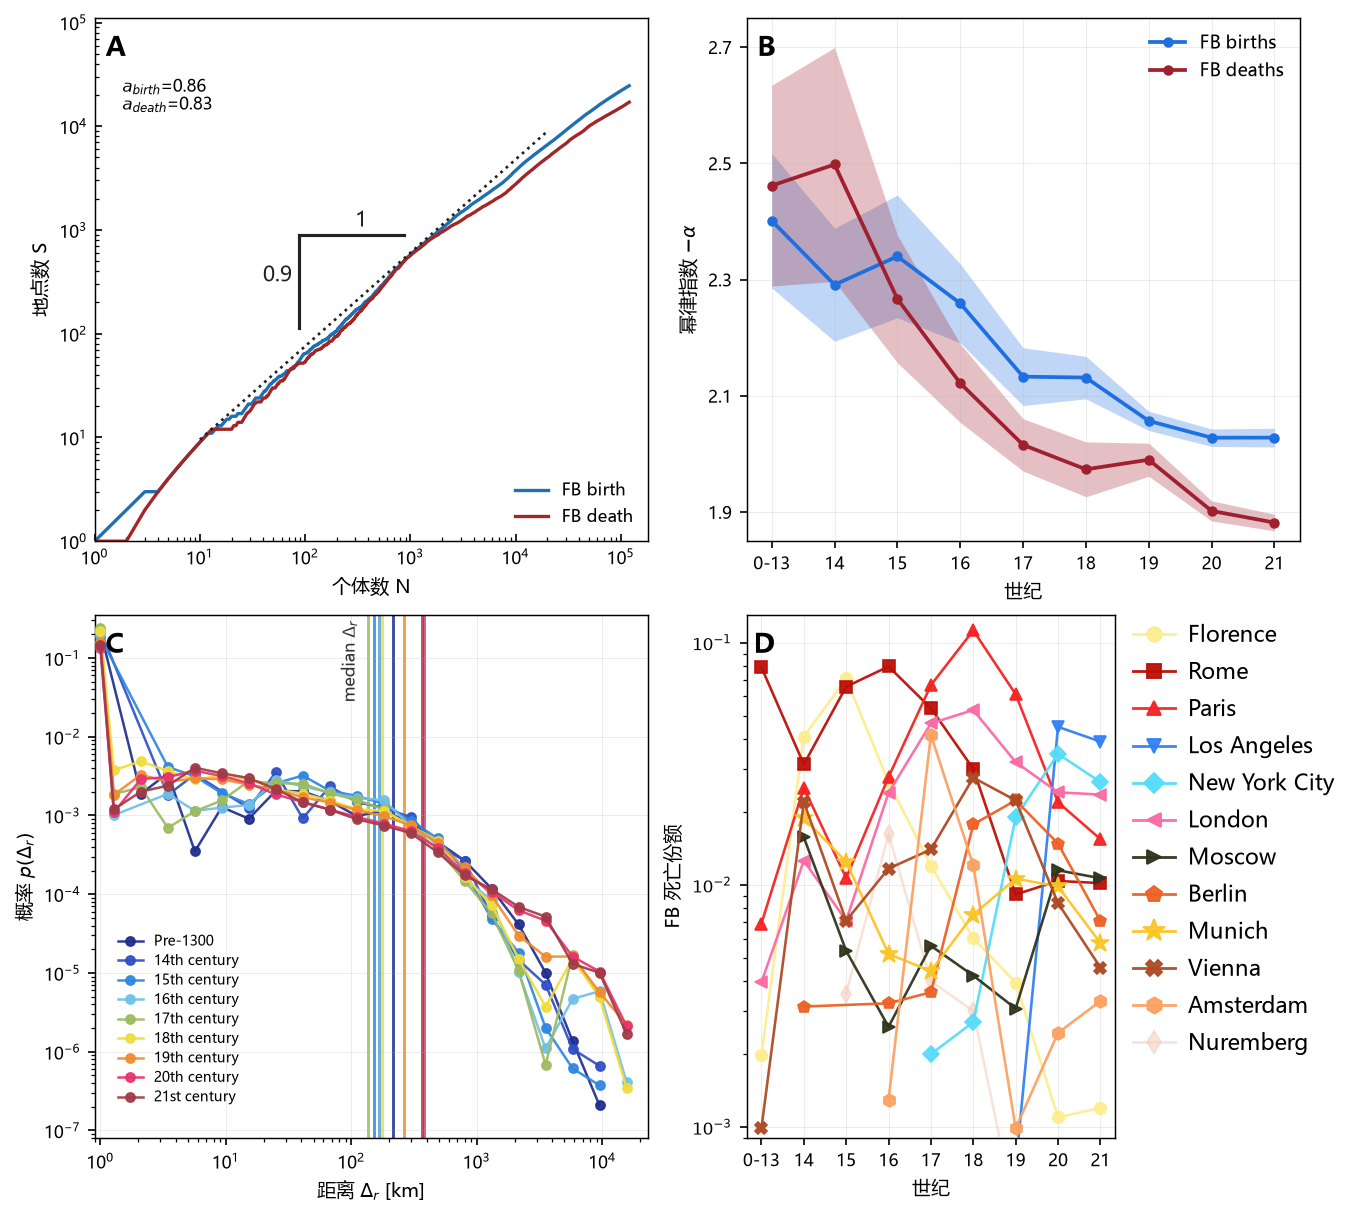

In [7]:
# ---------- 6. 绘图：2×2 合并 ----------

fig, axes = plt.subplots(2, 2, figsize=(10.2, 8.0), dpi = 150,  constrained_layout=True)
(axA, axB), (axC, axD) = axes

# ---- A：Heaps 律（双 log、点线 = N^0.9、L 形斜率标注）
for n, s, c, lab in [(nb_, sb, C_BLUE, "FB birth"), (nd, sd, C_RED, "FB death")]:
    axA.loglog(n, s, color=c, lw=1.6, label=lab)
nr = np.logspace(1.0, np.log10(2.0e4), 60)
axA.loglog(nr, 1.2 * nr ** 0.9, color="#222", lw=1.3, ls=":")
n1, s1 = 88.0, 900.0                                  # L 形标注（横臂 1 decade）
axA.plot([n1, n1 * 10], [s1, s1], color="#222", lw=1.5)
axA.plot([n1, n1], [s1, s1 * 10 ** -0.9], color="#222", lw=1.5)
axA.annotate("1", (n1 * 3.4, s1 * 1.2), fontsize=10, color="#222")
axA.annotate("0.9", (n1 * 0.85, s1 * 10 ** -0.45), fontsize=10, color="#222",
             ha="right")
axA.set_xlim(1, 1.8e5)
axA.set_ylim(1, 1.1e5)
axA.set_xlabel("个体数 N")
axA.set_ylabel("地点数 S")
axA.tick_params(which="both", direction="in")
axA.grid(False)
axA.legend(loc="lower right", frameon=False, fontsize=8)
axA.text(0.05, 0.885, f"$a_{{birth}}$={a_birth:.2f}\n$a_{{death}}$={a_death:.2f}",
         transform=axA.transAxes, fontsize=8, va="top", ha="left")

# ---- B：幂律指数（线性 y 轴、右上角图例）
x = np.arange(9)
B_BLUE, B_RED = "#1F6FE0", "#A02030"
axB.fill_between(x, slope_df.slope_birth - slope_df.se_birth,
                 slope_df.slope_birth + slope_df.se_birth,
                 color=B_BLUE, alpha=0.28, lw=0)
axB.fill_between(x, slope_df.slope_death - slope_df.se_death,
                 slope_df.slope_death + slope_df.se_death,
                 color=B_RED, alpha=0.28, lw=0)
axB.plot(x, slope_df.slope_birth, "-o", color=B_BLUE, ms=4, lw=1.8, label="FB births")
axB.plot(x, slope_df.slope_death, "-o", color=B_RED, ms=4, lw=1.8, label="FB deaths")
axB.set_xticks(x)
axB.set_xticklabels(CENT)
axB.set_xlabel("世纪")
axB.set_ylabel("幂律指数 $-\\alpha$")
axB.set_ylim(1.85, 2.75)
axB.set_yticks([1.9, 2.1, 2.3, 2.5, 2.7])
axB.legend(loc="upper right", frameon=False, fontsize=8.5)

# ---- C：距离分布（彩虹色系、x=1 同城尖峰、median 竖线）
COLORS_C = ["#1F2D8C", "#2E4FC7", "#2E86E0", "#6FC0E8", "#9DBB5F",
            "#F0DC3C", "#F08C2E", "#E8336E", "#A03A48"]
LEGEND_C = ["Pre-1300", "14th century", "15th century", "16th century",
            "17th century", "18th century", "19th century", "20th century",
            "21st century"]
for i, c in enumerate(BINS):
    d = sub[sub.dcent == c].dr.values
    n_all_c = len(d)                               # 分母 = 该世纪全部记录（含同城）
    h, _ = np.histogram(d, bins=EDGES)
    pdf = h / (n_all_c * widths)
    pdf0 = (d < 1).sum() / n_all_c                 # Δr<1km → x=1 尖峰
    xs = np.concatenate([[1.0], centers])
    ys = np.concatenate([[pdf0], pdf])
    m = ys > 0                                     # 空 bin 不画（log 轴 y=0 → −∞）
    if m.sum() < 3:
        continue
    axC.loglog(xs[m], ys[m], "-o", color=COLORS_C[i], lw=1.2, ms=4.2,
               alpha=0.92, label=LEGEND_C[i], zorder=3)
for i, c in enumerate(BINS):
    if c in med_by_bin.index and np.isfinite(med_by_bin[c]):
        axC.axvline(med_by_bin[c], color=COLORS_C[i], lw=1.4, alpha=0.85, zorder=1)
axC.text(med_by_bin.min() * 0.86, 0.3, "median $\\Delta_r$", rotation=90,
         fontsize=8, color="#333", va="top", ha="right")
axC.set_xlim(0.9, 2.3e4)
axC.set_ylim(8e-8, 0.35)
axC.set_xlabel("距离 $\\Delta_r$ [km]")
axC.set_ylabel("概率 $p(\\Delta_r)$")
axC.legend(loc="lower left", bbox_to_anchor=(0.02, 0.04), frameon=False,
           fontsize=6.6, handlelength=1.8, labelspacing=0.35)

# ---- D：死亡份额（log y、形状+颜色双编码、图例置于面板右侧）
MS_OF = {"*": 9.0, "p": 6.2, "h": 6.2, "X": 6.2, "d": 6.0, "D": 5.4}
for k, (name, c, faded, mk, ls) in CITY_KEY.items():
    if k not in share.columns:
        continue
    y = share[k].values.astype(float)
    m = y > 0
    axD.plot(x[m], y[m], ls=ls, marker=mk, color=c, ms=MS_OF.get(mk, 5.6),
             lw=1.25, mec=c, mew=0.8,
             alpha=0.55 if faded else 0.95, zorder=3 if faded else 4)
axD.set_yscale("log")
axD.set_xticks(x)
axD.set_xticklabels(CENT)
axD.set_xlim(-0.35, 8.35)
axD.set_ylim(9e-4, 0.13)
axD.set_yticks([1e-3, 1e-2, 1e-1])
axD.set_yticklabels(["$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
axD.set_xlabel("世纪")
axD.set_ylabel("FB 死亡份额")
axD.legend([plt.Line2D([], [], color=c, marker=mk, ms=MS_OF.get(mk, 5.6) * 1.25,
                       lw=1.35, ls=ls, mec=c, mew=0.9, alpha=0.55 if f else 0.95)
            for _, (name, c, f, mk, ls) in CITY_KEY.items()],
           [name for _, (name, c, f, mk, ls) in CITY_KEY.items()],
           loc="upper left", bbox_to_anchor=(1.025, 1.0), frameon=False,
           fontsize=10.5, handletextpad=0.6, labelspacing=0.62, borderaxespad=0,
           handlelength=1.9)

# D 面板缩窄 1/3：先完成布局，再手动缩窄并冻结
fig.canvas.draw()
p = axD.get_position()
axD.set_position([p.x0, p.y0, p.width * 2 / 3, p.height])
fig.set_constrained_layout(False)

# 面板标号
for ax, lab in [(axA, "A"), (axB, "B"), (axC, "C"), (axD, "D")]:
    ax.text(0.02, 0.97, lab, transform=ax.transAxes, fontsize=13,
            fontweight="bold", va="top", ha="left")

plt.show()



In [8]:
out_png = FIG / "fig2_four_panels_notebook.pdf"
fig.savefig(out_png, bbox_inches="tight", facecolor="white")
print("saved:", out_png)

res = {
    "heaps_exponent_birth": round(a_birth, 3),
    "heaps_exponent_death": round(a_death, 3),
    "paper_heaps_exponent": 0.9,
    "powerlaw_gamma_by_century": slope_df.round(3).to_dict("records"),
    "fig2b_version_note": "powerlaw 库版本的 KS 自动搜索在 KS 相近处会翻转 xmin 选择，"
                          "导致 γ 随之系统性移动（本环境与另环境复现差约 0.1）；"
                          "gamma_*_fixed 列为固定 SM fig. S10G 标注 xmin 的 zeta MLE 对照",
    "median_distance_km_by_bin": {BIN_LABELS[i]: round(float(med_by_bin[c]), 1)
                                  for i, c in enumerate(BINS)
                                  if c in med_by_bin.index and np.isfinite(med_by_bin[c])},
    "paper_median_distance": {"14th": 214, "17th": 135, "21st": 382},
    "same_location_share": round(float((fb.bkey == fb.dkey).mean()), 3),
    "distance_sample_incl_same_place": int(len(sub)),
    "paris_death_share": share["paris"].round(4).to_dict(),
    "fig2a_method": "参数曲线 (N(t),S(t))：N=按年累计个体数，S=累计不同地点数（expanding 去重）",
    "fig2b_method": "ante 累计箱 + 离散幂律 MLE，xmin 由 KS 最小化自动选择（powerlaw 包）",
    "fig2c_method": "对数分箱 20 箱（1→2×10⁴ km）；Δr<1km（同城）单独成箱画在 x=1",
    "fig2d_method": "单世纪箱死亡份额，12 城，颜色与标记取自原图",
}
json.dump(res, open(HERE / "results_fig2_notebook.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1)
print("saved results_fig2_notebook.json")

saved: D:\BaiduSyncdisk\Research\结构建模书稿章节\output\schich-repro\figures\fig2_four_panels_notebook.pdf
saved results_fig2_notebook.json
